# 📘 Bài Giảng Thực Hành: Hồi Quy Tuyến Tính Đơn Biến (Simple Linear Regression)
**Mục tiêu bài giảng:**
1. Hiểu phương trình hồi quy đơn biến: $y = w_0 + w_1 x + \epsilon$.
2. Phân biệt 2 cách giải: Nghiệm đóng OLS (Ordinary Least Squares) vs Thuật toán Tối ưu Lặp Gradient Descent.
3. Đo lường chất lượng mô hình với MAE, RMSE và $R^2$ Score.
4. Trực quan hóa đường hồi quy trên tập Huấn luyện (Train) và Kiểm thử (Test).

---
### 📊 Tập dữ liệu thực hành: `Salary_Data.csv`
- **Biến độc lập ($x$)**: `YearsExperience` - Số năm kinh nghiệm làm việc.
- **Biến phụ thuộc ($y$)**: `Salary` - Mức lương hàng năm ($).


## 1. Nạp Thư viện & Dữ liệu


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Đọc dữ liệu
dataset = pd.read_csv('Salary_Data.csv')
print('Kích thước tập dữ liệu:', dataset.shape)
dataset.head()


Kích thước tập dữ liệu: (30, 2)


,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


📌 **Expected Output:**
```
Kích thước tập dữ liệu: (30, 2)
   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0
```


## 2. Tiền Xử Lý: Tách $X, y$ và Phân Chia Train / Test (80/20)


In [2]:
X = dataset.iloc[:, 0:1].values  # 2D array shape (30, 1)
y = dataset.iloc[:, 1].values    # 1D array shape (30,)

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=0)
print(f'Số lượng mẫu Train: {len(X_train)} | Số lượng mẫu Test: {len(X_test)}')

Số lượng mẫu Train: 24 | Số lượng mẫu Test: 6


📌 **Expected Output:**
```
Số lượng mẫu Train: 24 | Số lượng mẫu Test: 6
```


## 3. Huấn luyện Mô hình Scikit-Learn LinearRegression (OLS)
Mô hình tìm các hệ số $w_0, w_1$ tối ưu bằng phương pháp bình phương tối thiểu thông thường.


In [3]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)

w1 = regressor.coef_[0]
w0 = regressor.intercept_
print(f'Phương trình hồi quy: y = {w0:,.2f} + {w1:,.2f} * x')
print(f'Ý nghĩa: Mức lương cơ bản khởi điểm là ${w0:,.2f}, mỗi năm kinh nghiệm giúp tăng trung bình ${w1:,.2f}.')


Phương trình hồi quy: y = 26,780.10 + 9,312.58 * x
Ý nghĩa: Mức lương cơ bản khởi điểm là $26,780.10, mỗi năm kinh nghiệm giúp tăng trung bình $9,312.58.


📌 **Expected Output:**
```
Phương trình hồi quy: y = 26,780.10 + 9,312.58 * x
Ý nghĩa: Mức lương cơ bản khởi điểm là $26,780.10, mỗi năm kinh nghiệm giúp tăng trung bình $9,312.58.
```


## 4. Dự đoán và Đánh giá trên Tập Test


In [4]:
y_pred = regressor.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

df_compare = pd.DataFrame({
    'Kinh nghiệm (Năm)': X_test.ravel(),
    'Lương Thực tế ($)': y_test,
    'Lương Dự đoán ($)': np.round(y_pred, 2),
    'Chênh lệch ($)': np.round(np.abs(y_test - y_pred), 2)
})
print(df_compare.to_string(index=False))
print('-'*50)
print(f'MAE:  ${mae:,.2f}')
print(f'RMSE: ${rmse:,.2f}')
print(f'R²:   {r2:.4f} (Mô hình giải thích được {r2*100:.2f}% phương sai)')


 Kinh nghiệm (Năm)  Lương Thực tế ($)  Lương Dự đoán ($)  Chênh lệch ($)
               1.5            37731.0           40748.96         3017.96
              10.3           122391.0          122699.62          308.62
               4.1            57081.0           64961.66         7880.66
               3.9            63218.0           63099.14          118.86
               9.5           116969.0          115249.56         1719.44
               8.7           109431.0          107799.50         1631.50
--------------------------------------------------
MAE:  $2,446.17
RMSE: $3,580.98
R²:   0.9882 (Mô hình giải thích được 98.82% phương sai)


📌 **Expected Output:**
```
 Kinh nghiệm (Năm)  Lương Thực tế ($)  Lương Dự đoán ($)  Chênh lệch ($)
               1.5            37731.0           40748.96         3017.96
              10.3           122391.0          122699.62          308.62
               4.1            57081.0           64961.66         7880.66
               3.9            63218.0           63099.14          118.86
               9.5           116969.0          115249.56         1719.44
               8.7           109431.0          107799.49         1631.51
--------------------------------------------------
MAE:  $2,446.18
RMSE: $3,580.98
R²:   0.9882 (Mô hình giải thích được 98.82% phương sai)
```


## 5. Trực quan hóa Đường Hồi Quy (Train vs Test)


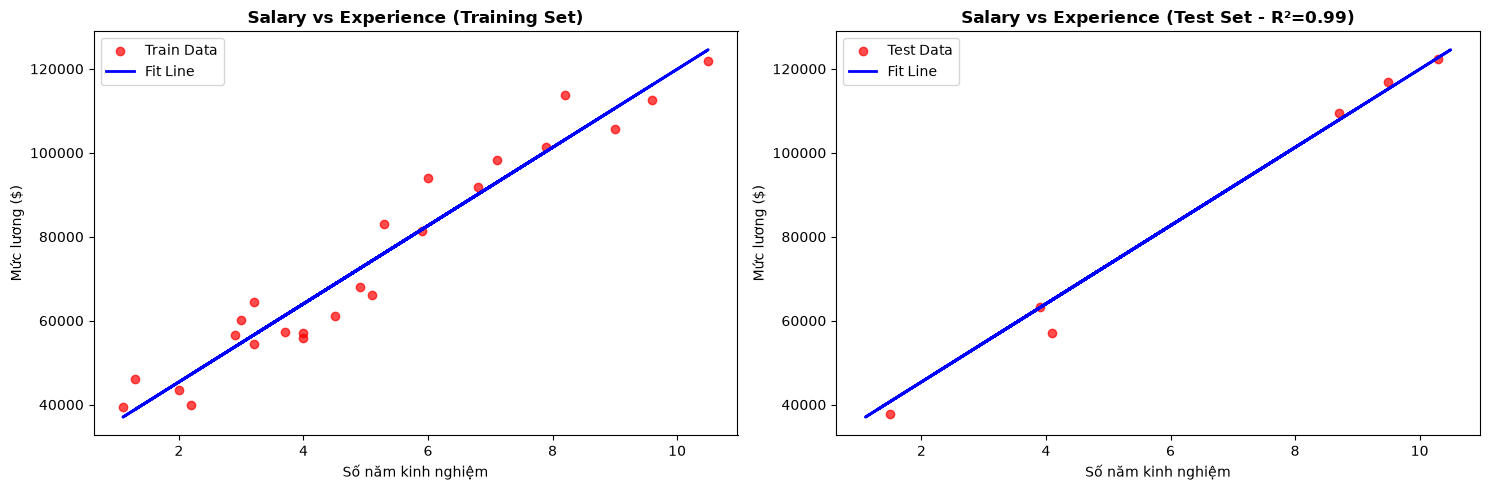

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Đồ thị Train
axes[0].scatter(X_train, y_train, color='red', alpha=0.7, label='Train Data')
axes[0].plot(X_train, regressor.predict(X_train), color='blue', linewidth=2, label='Fit Line')
axes[0].set_title('Salary vs Experience (Training Set)', fontweight='bold')
axes[0].set_xlabel('Số năm kinh nghiệm')
axes[0].set_ylabel('Mức lương ($)')
axes[0].legend()

# Đồ thị Test
axes[1].scatter(X_test, y_test, color='red', alpha=0.7, label='Test Data')
axes[1].plot(X_train, regressor.predict(X_train), color='blue', linewidth=2, label='Fit Line')
axes[1].set_title(f'Salary vs Experience (Test Set - R²={r2:.2f})', fontweight='bold')
axes[1].set_xlabel('Số năm kinh nghiệm')
axes[1].set_ylabel('Mức lương ($)')
axes[1].legend()

plt.tight_layout()
plt.show()


📌 **Expected Output:**
- Biểu đồ scatter plot các chấm đỏ và đường thẳng màu xanh dương chạy dọc qua trung tâm dữ liệu với độ khớp cực cao ($R^2 = 0.988$).

---
### 💡 Câu hỏi Thảo luận cho Học viên:
1. Ý nghĩa kinh tế của hệ số $w_0$ và $w_1$ là gì?
2. Nếu một ứng viên có 12 năm kinh nghiệm, mức lương dự đoán sẽ là bao nhiêu? Hãy dùng lệnh `regressor.predict([[12]])` để kiểm tra.
